# Smart Crop Planning & Companion Planting

Notebook d'aide à la décision pour choisir les cultures, les associer et les répartir dans une parcelle, avec une couche agrivoltaïque.

> Fonctionnement entièrement local : aucune API externe n'est appelée.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

try:
    from scipy.optimize import linprog
except ImportError:
    linprog = None

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)

## 1. Charger les cultures

Le fichier `data/crops.json` est utilisé lorsqu'il existe. Sinon, une base de démonstration permet d'exécuter immédiatement le notebook.

In [2]:
crop_file = Path("data/crops.json")
if crop_file.exists():
    with crop_file.open("r", encoding="utf-8") as f:
        crops_raw = json.load(f)
else:
    crops_raw = {
        "lettuce": {"name_fr":"Laitue","family":"Astéracées","root_depth_m":0.3,"light_need":"low","n_fixer":0,"kc_mid":1.0},
        "tomato": {"name_fr":"Tomate","family":"Solanacées","root_depth_m":1.0,"light_need":"high","n_fixer":0,"kc_mid":1.15},
        "bean": {"name_fr":"Haricot","family":"Fabacées","root_depth_m":0.7,"light_need":"medium","n_fixer":1,"kc_mid":1.15},
        "onion": {"name_fr":"Oignon","family":"Alliacées","root_depth_m":0.4,"light_need":"high","n_fixer":0,"kc_mid":1.05},
        "spinach": {"name_fr":"Épinard","family":"Amaranthacées","root_depth_m":0.5,"light_need":"medium","n_fixer":0,"kc_mid":1.0}
    }

rows = []
for crop_id, c in crops_raw.items():
    rows.append({
        "crop_id": crop_id,
        "culture": c.get("name_fr", crop_id),
        "famille": c.get("family", "Inconnue"),
        "racines_m": c.get("root_depth_m", 0.6),
        "lumiere": c.get("light_need", "medium"),
        "fixe_azote": c.get("n_fixer", 0),
        "kc_milieu": c.get("kc_mid", 1.0)
    })
crops = pd.DataFrame(rows)
crops

,crop_id,culture,famille,racines_m,lumiere,fixe_azote,kc_milieu
0,tomato,Tomate,Solanacées,1.0,high,0,1.15
1,pepper,Poivron / piment,Solanacées,0.8,high,0,1.05
2,eggplant,Aubergine,Solanacées,0.9,high,0,1.05
3,potato,Pomme de terre,Solanacées,0.5,high,0,1.15
4,onion,Oignon,Alliacées,0.4,high,0,1.05
5,garlic,Ail,Alliacées,0.4,high,0,1.00
6,melon,Melon,Cucurbitacées,1.0,high,0,1.05
7,watermelon,Pastèque,Cucurbitacées,1.0,high,0,1.00
8,cucumber,Concombre,Cucurbitacées,0.8,high,0,1.00
9,carrot,Carotte,Apiacées,0.7,medium,0,1.05


## 2. Définir la parcelle

Modifiez ces paramètres pour simuler une autre ferme, un autre scénario sec ou une autre couverture photovoltaïque.

In [3]:
farm = {
    "surface_ha": 10.0,
    "eau_disponible_m3": 35000.0,
    "pluie_annuelle_mm": 420,
    "temperature_moyenne_c": 24,
    "pH": 7.1,
    "ndvi_moyen": 0.68,
    "ensoleillement_pct": 78,
    "couverture_panneaux_pct": 30,
}
pd.Series(farm, name="Valeur")

surface_ha                    10.00
eau_disponible_m3          35000.00
pluie_annuelle_mm            420.00
temperature_moyenne_c         24.00
pH                             7.10
ndvi_moyen                     0.68
ensoleillement_pct            78.00
couverture_panneaux_pct       30.00
Name: Valeur, dtype: float64

## 3. Scoring multicritère

Le score est pondéré entre climat, sol, eau, vigueur satellite, marché et résilience. Les valeurs de marché sont simulées uniquement pour la démonstration.

In [4]:
weights = {"climat": 0.25, "sol": 0.20, "eau": 0.20, "satellite": 0.15, "marche": 0.15, "resilience": 0.05}
rng = np.random.default_rng(42)
market = {row["culture"]: float(rng.uniform(0.45, 0.95)) for _, row in crops.iterrows()}

def trapezoid(x, low, opt_low, opt_high, high):
    x = np.asarray(x)
    out = np.zeros_like(x, dtype=float)
    left = (low <= x) & (x < opt_low)
    right = (opt_high < x) & (x <= high)
    plateau = (opt_low <= x) & (x <= opt_high)
    out[left] = (x[left] - low) / (opt_low - low)
    out[plateau] = 1.0
    out[right] = (high - x[right]) / (high - opt_high)
    out[(x < low) | (x > high)] = 0.0
    return float(np.clip(out, 0, 1).item()) if np.asarray(out).size == 1 else np.clip(out, 0, 1)

def rank_crops(crops, farm, weights, market):
    result = crops.copy()
    light_ranges = {"high": (18,22,30,36), "medium": (12,18,28,34), "low": (8,14,24,30)}
    result["besoin_eau_m3_ha"] = np.select(
        [result["lumiere"] == "high", result["lumiere"] == "medium"],
        [7000 * result["kc_milieu"], 5200 * result["kc_milieu"]],
        default=4000 * result["kc_milieu"]
    )
    result["climat"] = result["lumiere"].map(lambda l: trapezoid(farm["temperature_moyenne_c"], *light_ranges[l]))
    result["sol"] = np.clip(1 - abs(farm["pH"] - 6.5) / 4, 0.25, 1)
    available = farm["pluie_annuelle_mm"] * 10 + farm["eau_disponible_m3"] / farm["surface_ha"]
    result["eau"] = np.clip(available / result["besoin_eau_m3_ha"], 0, 1)
    result["satellite"] = np.clip(farm["ndvi_moyen"] * (1 - 0.15 * (result["racines_m"] > 0.8)), 0, 1)
    result["marche"] = result["culture"].map(market).fillna(0.5)
    result["resilience"] = np.clip(0.55 + 0.25 * result["fixe_azote"] + rng.uniform(0.05, 0.20, len(result)), 0, 1)
    result["score"] = sum(result[k] * v for k, v in weights.items())
    return result.sort_values("score", ascending=False)

ranking = rank_crops(crops, farm, weights, market)
ranking[["culture","score","climat","sol","eau","satellite","marche","resilience","besoin_eau_m3_ha"]].round(3)

,culture,score,climat,sol,eau,satellite,marche,resilience,besoin_eau_m3_ha
18,Pois chiche,0.899,1.0,0.85,1.000,0.680,0.864,0.950,7000.0
5,Ail,0.896,1.0,0.85,1.000,0.680,0.938,0.666,7000.0
11,Chou,0.892,1.0,0.85,1.000,0.680,0.913,0.658,5460.0
23,Fraise,0.888,1.0,0.85,1.000,0.680,0.897,0.621,4420.0
31,Figuier,0.881,1.0,0.85,1.000,0.578,0.934,0.684,5600.0
19,Petit pois,0.876,1.0,0.85,0.957,0.680,0.766,0.956,8050.0
22,Patate douce,0.873,1.0,0.85,0.957,0.578,0.935,0.685,8050.0
2,Aubergine,0.872,1.0,0.85,1.000,0.578,0.879,0.671,7350.0
20,Soja,0.871,1.0,0.85,0.957,0.578,0.829,0.967,8050.0
12,Radis / daikon,0.870,1.0,0.85,1.000,0.680,0.772,0.643,4680.0


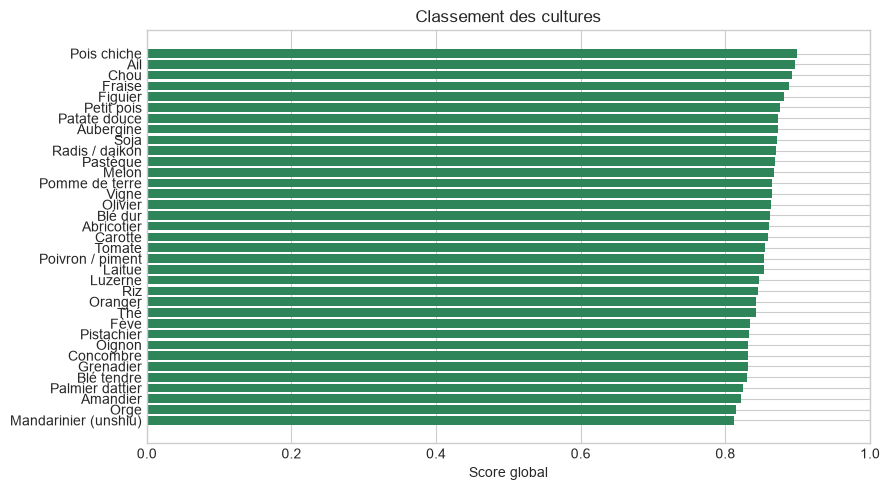

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ranking["culture"], ranking["score"], color="#2f855a")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title("Classement des cultures")
ax.set_xlabel("Score global")
plt.tight_layout()
plt.show()

## 4. Compatibilité entre cultures

La compatibilité tient compte de la famille botanique, des besoins en eau, des racines, de l'azote fixé et de la lumière.

In [6]:
def compatibility(a, b):
    if a["famille"] == b["famille"]:
        return 0.35, "Même famille : risque sanitaire et compétition similaires"
    score = 0.55
    reasons = []
    if a["fixe_azote"] or b["fixe_azote"]:
        score += 0.15
        reasons.append("fixation de l'azote bénéfique")
    if abs(a["racines_m"] - b["racines_m"]) >= 0.25:
        score += 0.15
        reasons.append("racines complémentaires")
    if a["lumiere"] != b["lumiere"]:
        score += 0.10
        reasons.append("peut exploiter des étages lumineux différents")
    return min(score, 1.0), "; ".join(reasons) if reasons else "compétition modérée"

pairs = []
for _, a in crops.iterrows():
    for _, b in crops.iterrows():
        if a["crop_id"] < b["crop_id"]:
            score, reason = compatibility(a, b)
            pairs.append({"culture_1": a["culture"], "culture_2": b["culture"], "compatibilite": score, "raison": reason})

pairs_df = pd.DataFrame(pairs).sort_values("compatibilite", ascending=False)
pairs_df

,culture_1,culture_2,compatibilite,raison
367,Luzerne,Radis / daikon,0.95,fixation de l'azote bénéfique; racines complém...
364,Luzerne,Carotte,0.95,fixation de l'azote bénéfique; racines complém...
365,Luzerne,Laitue,0.95,fixation de l'azote bénéfique; racines complém...
366,Luzerne,Chou,0.95,fixation de l'azote bénéfique; racines complém...
388,Luzerne,Thé,0.95,fixation de l'azote bénéfique; racines complém...
...,...,...,...,...
101,Concombre,Melon,0.35,Même famille : risque sanitaire et compétition...
102,Concombre,Pastèque,0.35,Même famille : risque sanitaire et compétition...
82,Melon,Pastèque,0.35,Même famille : risque sanitaire et compétition...
61,Ail,Oignon,0.35,Même famille : risque sanitaire et compétition...


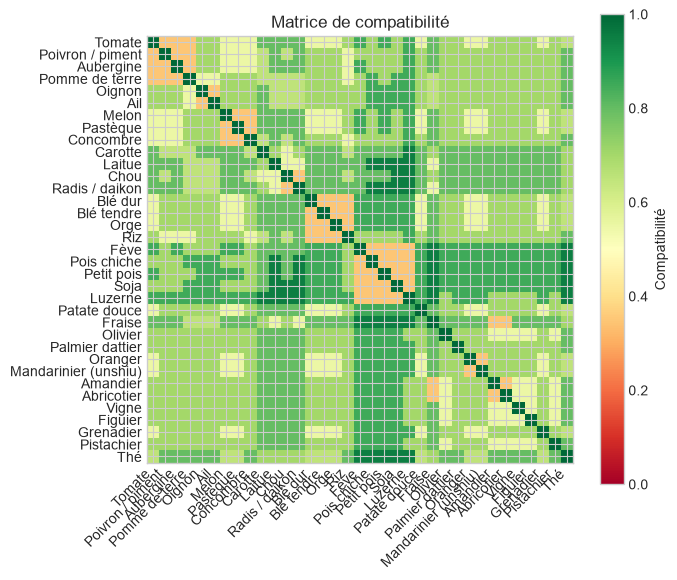

In [7]:
labels = crops["culture"].tolist()
matrix = pd.DataFrame(1.0, index=labels, columns=labels)
for _, a in crops.iterrows():
    for _, b in crops.iterrows():
        if a["culture"] != b["culture"]:
            matrix.loc[a["culture"], b["culture"]] = compatibility(a, b)[0]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matrix, vmin=0, vmax=1, cmap="RdYlGn")
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Matrice de compatibilité")
plt.colorbar(im, ax=ax, label="Compatibilité")
plt.tight_layout()
plt.show()

## 5. Allocation optimale de la parcelle

On sélectionne les 2 à 4 cultures les mieux compatibles avec l'objectif global, puis on optimise leurs surfaces sous contraintes de surface totale et d'eau.

In [8]:
selected = ranking.head(4).copy()

def allocate_land(selected, farm):
    n = len(selected)
    c = -selected["score"].to_numpy()
    if linprog is not None:
        res = linprog(
            c,
            A_ub=np.vstack([np.ones(n), selected["besoin_eau_m3_ha"].to_numpy()]),
            b_ub=np.array([farm["surface_ha"], farm["eau_disponible_m3"]]),
            bounds=[(0, farm["surface_ha"])] * n,
            method="highs",
        )
        areas = res.x if res.success else np.ones(n) * farm["surface_ha"] / n
    else:
        areas = np.ones(n) * farm["surface_ha"] / n
    result = selected[["culture","score","besoin_eau_m3_ha"]].copy()
    result["surface_ha"] = areas
    result["eau_m3"] = areas * result["besoin_eau_m3_ha"]
    result = result[result["surface_ha"] > 1e-8]
    return result

allocation = allocate_land(selected, farm)
allocation.round(3)

,culture,score,besoin_eau_m3_ha,surface_ha,eau_m3
23,Fraise,0.888,4420.0,7.919,35000.0


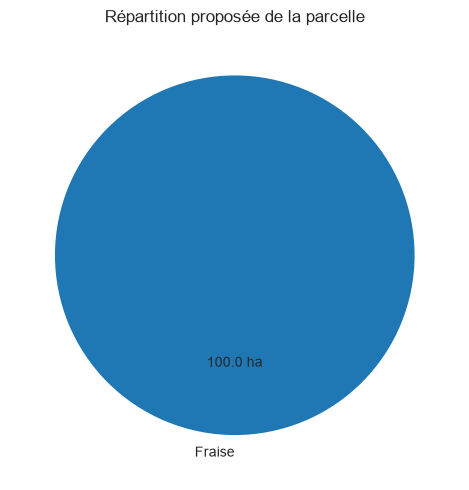

Surface allouée : 7.92 ha
Eau nécessaire : 35,000 m³


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.pie(allocation["surface_ha"], labels=allocation["culture"], autopct="%1.1f ha", startangle=90)
ax.set_title("Répartition proposée de la parcelle")
plt.tight_layout()
plt.show()

print(f"Surface allouée : {allocation['surface_ha'].sum():.2f} ha")
print(f"Eau nécessaire : {allocation['eau_m3'].sum():,.0f} m³")

## 6. Agrivoltaïsme

Une culture tolérante à l'ombre, peu exigeante en lumière et à racines peu profondes est privilégiée sous les panneaux. Les zones ombrées doivent être adaptées à la hauteur réelle des structures.

In [10]:
def agrivoltaic_score(row, farm):
    shade_bonus = {"low": 1.0, "medium": 0.75, "high": 0.35}[row["lumiere"]]
    root_bonus = np.clip(1 - row["racines_m"] / 1.5, 0.2, 1)
    water_bonus = np.clip(row["kc_milieu"] / 1.2, 0.5, 1)
    shade_fraction = farm["couverture_panneaux_pct"] / 100
    microclimate_bonus = 0.15 * (1 - shade_fraction) + 0.85
    return 0.45 * shade_bonus + 0.25 * root_bonus + 0.15 * water_bonus + 0.15 * microclimate_bonus

crops_agr = crops.copy()
crops_agr["score_agrivoltaïque"] = crops_agr.apply(lambda r: agrivoltaic_score(r, farm), axis=1)
crops_agr.sort_values("score_agrivoltaïque", ascending=False)[["culture","lumiere","racines_m","score_agrivoltaïque"]].round(3)

,culture,lumiere,racines_m,score_agrivoltaïque
10,Laitue,medium,0.4,0.789
23,Fraise,medium,0.3,0.787
12,Radis / daikon,medium,0.4,0.777
11,Chou,medium,0.6,0.762
9,Carotte,medium,0.7,0.745
34,Thé,medium,1.2,0.656
4,Oignon,high,0.4,0.615
3,Pomme de terre,high,0.5,0.611
5,Ail,high,0.4,0.609
17,Fève,high,0.6,0.594


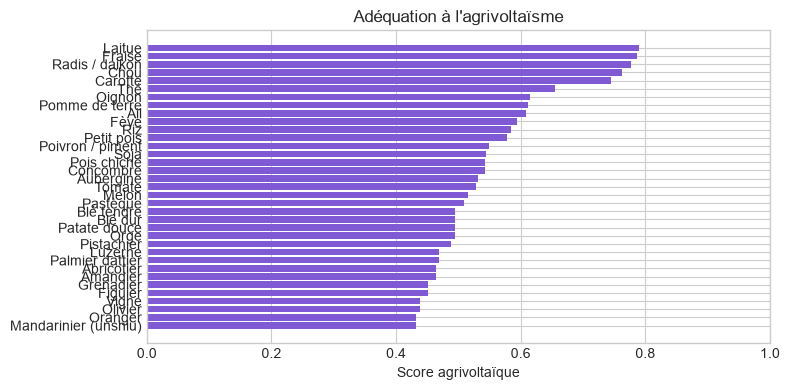

In [11]:
agr = crops_agr.sort_values("score_agrivoltaïque", ascending=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(agr["culture"], agr["score_agrivoltaïque"], color="#805ad5")
ax.set_xlim(0, 1)
ax.set_title("Adéquation à l'agrivoltaïsme")
ax.set_xlabel("Score agrivoltaïque")
plt.tight_layout()
plt.show()

## 7. Zones de plantation simplifiées

Carte conceptuelle : les cultures allouées sont placées en bandes proportionnelles à leur surface. À remplacer par les polygones Sentinel-2 / parcelle réels.

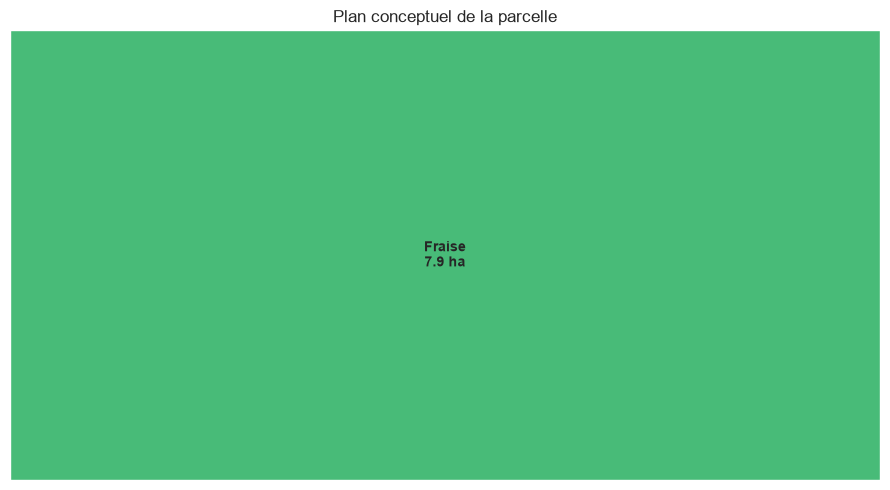

In [12]:
palette = ["#48bb78", "#4299e1", "#ecc94b", "#ed8936", "#9f7aea"]
fig, ax = plt.subplots(figsize=(9, 5))
x0 = 0
for i, row in allocation.reset_index(drop=True).iterrows():
    width = row["surface_ha"]
    ax.add_patch(plt.Rectangle((x0, 0), width, 1, color=palette[i % len(palette)], ec="white"))
    ax.text(x0 + width/2, 0.5, f'{row["culture"]}\n{width:.1f} ha', ha="center", va="center", fontweight="bold")
    x0 += width
ax.set_xlim(0, allocation["surface_ha"].sum())
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Plan conceptuel de la parcelle")
plt.tight_layout()
plt.show()

## 8. Synthèse et limites

- Résultat à valider avec un agronome, surtout pour les semis, les seuils de sel et les maladies.
- Les données marché, météo détaillée et satellite doivent être remplacées par les services de production.
- Les valeurs EcoCrop du projet sont plus fiables que les données simulées utilisées dans les graphiques.
- Le modèle est une aide à la décision, pas une prescription agronomique automatique.